In [1]:
%pip install pandas matplotlib seaborn numpy
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

Note: you may need to restart the kernel to use updated packages.


# 05. Grand Slam trends

This chapter asks three simple questions about the 80 Slams from 2000 to 2019. Who won, by surface? Did the best ranked player usually win? And how often did the lower ranked player win, which is what an upset means in this project?

In [2]:
import os
PROC = os.path.join('..', 'data', 'processed')
CH = os.path.join('..', 'charts')
os.makedirs(CH, exist_ok=True)

## Titles by surface, and a warning about seeds

The original files have no seed column, so this chapter uses rank at match time instead, and says so. Rank 1 means the world number 1 at that time. A low seed and a low rank usually point the same way, but they are not the same thing, so any sentence about seeds here is really about ranks.

In [3]:
fin = pd.read_csv(f'{PROC}/slam_finals_2000_2019.csv')
print('Titles by Slam:'); print(fin.groupby('tournament').size())
print('Titles by surface:'); print(fin.groupby('surface').size())
def band(r):
    if r == 1: return 'Rank 1'
    if r <= 4: return 'Rank 2 to 4'
    if r <= 10: return 'Rank 5 to 10'
    if r <= 32: return 'Rank 11 to 32'
    return 'Rank 33 plus'
fin['band'] = fin['rank'].apply(band)
print(fin.groupby('band').size())
print('Rank 1 winners:', (fin['rank'] == 1).sum(), 'of', len(fin))

Titles by Slam:
tournament
Australian Open    20
French Open        20
US Open            20
Wimbledon          20
dtype: int64
Titles by surface:
surface
Clay     20
Grass    20
Hard     40
dtype: int64
band
Rank 1           31
Rank 11 to 32     6
Rank 2 to 4      31
Rank 33 plus      2
Rank 5 to 10     10
dtype: int64
Rank 1 winners: 31 of 80


## Chart: Slam winners by rank band. The top four ranks won most Slams.

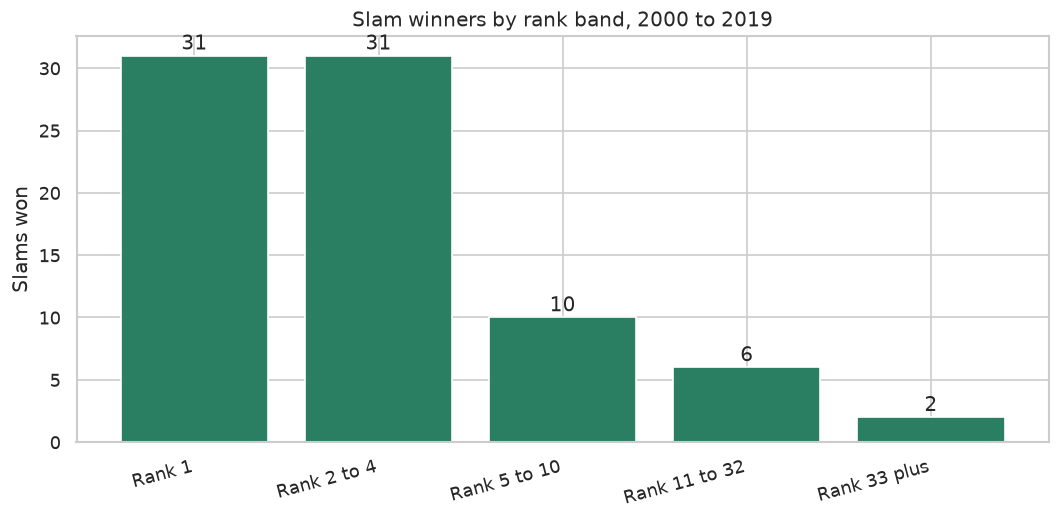

In [4]:
order = ['Rank 1', 'Rank 2 to 4', 'Rank 5 to 10', 'Rank 11 to 32', 'Rank 33 plus']
vals = [int((fin.band == b).sum()) for b in order]
plt.figure(figsize=(9, 4.5)); plt.bar(order, vals, color='#2a7f62')
plt.title('Slam winners by rank band, 2000 to 2019'); plt.ylabel('Slams won'); plt.xticks(rotation=15, ha='right')
for i, v in enumerate(vals): plt.text(i, v + 0.5, str(v), ha='center')
plt.tight_layout(); plt.savefig(f'{CH}/05_winners_by_rank_band.png'); plt.show()

## Upsets

An upset here means the winner had a worse rank number than the loser. Across all 10,120 matches with Stats rows, that happened 2,867 times, or 28.3 percent. Upsets are most common in the first round, at 30.4 percent, and rarer later, when the field is stronger. The final is the exception at 33.8 percent, but that is only 27 finals out of 80, so one or two finals move the number a lot. Do not over read the final bar.

In [5]:
up = pd.read_csv(f'{PROC}/slam_upsets.csv')
t = up.groupby('round')['upset'].agg(['mean', 'count', 'sum'])
print(t.round(3))
print('Overall upset rate:', round(up.upset.mean(), 4), 'on', len(up), 'matches')

                mean  count   sum
round                            
1st Round      0.304   5110  1553
2nd Round      0.255   2542   648
3rd Round      0.266   1273   339
4th Round      0.267    636   170
Quarterfinals  0.270    319    86
Semifinals     0.275    160    44
The Final      0.338     80    27
Overall upset rate: 0.2833 on 10120 matches


## Chart: upset rate by round.

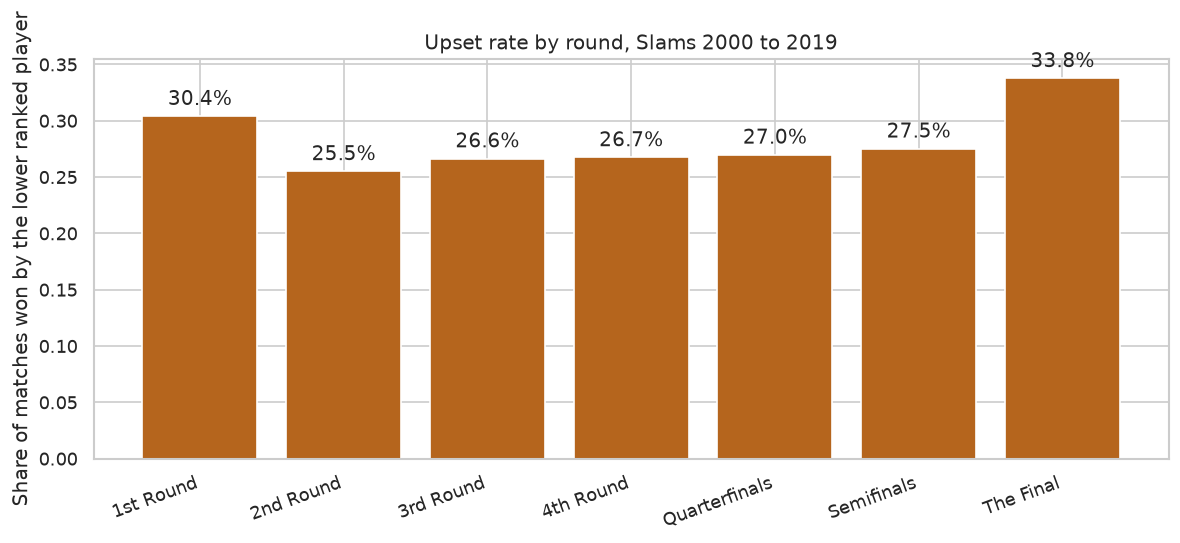

In [6]:
order = ['1st Round', '2nd Round', '3rd Round', '4th Round', 'Quarterfinals', 'Semifinals', 'The Final']
vals = [up[up['round'] == r].upset.mean() for r in order]
plt.figure(figsize=(10, 4.5)); plt.bar(order, vals, color='#b5651d')
plt.title('Upset rate by round, Slams 2000 to 2019'); plt.ylabel('Share of matches won by the lower ranked player'); plt.xticks(rotation=20, ha='right')
for i, v in enumerate(vals): plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.tight_layout(); plt.savefig(f'{CH}/05_upset_rate_by_round.png'); plt.show()

## Chart: how long matches lasted, by surface. Clay matches lasted longest on average.

          mean  median  count
surface                      
Clay     148.9   142.0   2533
Grass    133.2   129.0   2532
Hard     143.6   139.0   5052


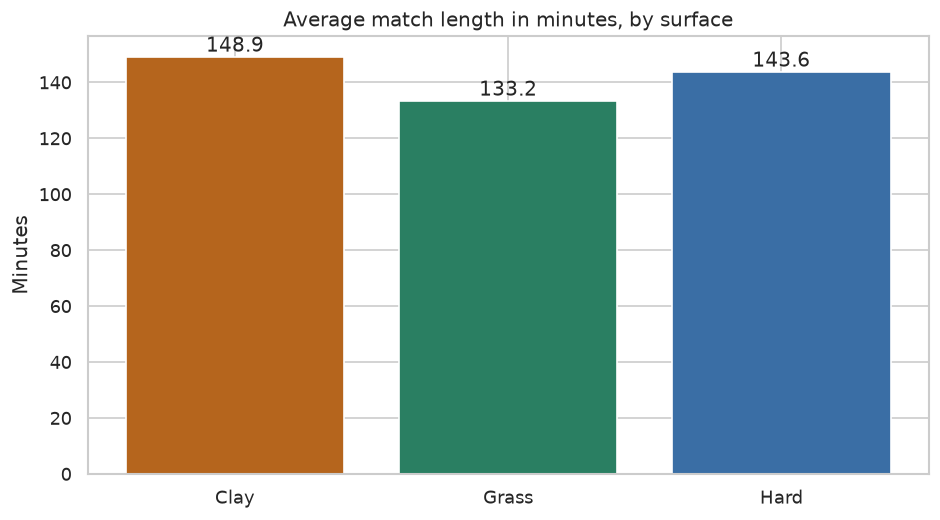

In [7]:
match = pd.read_csv('../data/raw/Match.csv')
match['surface'] = match.tournament.map({'Australian Open': 'Hard', 'French Open': 'Clay', 'US Open': 'Hard', 'Wimbledon': 'Grass'})
g = match.groupby('surface')['match_minutes'].agg(['mean', 'median', 'count'])
print(g.round(1))
plt.figure(figsize=(8, 4.5)); plt.bar(g.index, g['mean'], color=['#b5651d', '#2a7f62', '#3a6ea5'])
plt.title('Average match length in minutes, by surface'); plt.ylabel('Minutes')
for i, v in enumerate(g['mean']): plt.text(i, v + 2, f'{v:.1f}', ha='center')
plt.tight_layout(); plt.savefig(f'{CH}/05_match_minutes_by_surface.png'); plt.show()